## Data fetch and pre - processing



In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import datetime

file_path = "../data/indoor_office_temperatures.xlsx"
sensor_ids = [1383, 1395, 1469, 1487, 1493, 1499, 1553]

try:
  raw_data = pd.read_excel(file_path)
  for i in range(0, 7):
    t='timestamp'+str(sensor_ids[i])
    raw_data[t] = pd.to_datetime(raw_data[t])


except FileNotFoundError:
  print(f"File not found: {file_path}")
except Exception as e:
  print(f"An error occurred while loading the file: {e}")

In [35]:
raw_data.head()

,timestamp1383,s1383,timestamp1395,s1395,timestamp1469,s1469,timestamp1487,s1487,timestamp1493,s1493,timestamp1499,s1499,timestamp1553,s1553
0,2025-11-21 17:00:00,22.4,2025-11-21 17:00:00,22.5,2025-11-21 17:00:00,22.9,2025-11-21 17:00:00,23.5,2025-11-21 17:00:00,22.4,2025-11-21 17:00:00,22.6,2025-10-08 05:00:00,23.7
1,2025-11-21 16:00:00,22.5,2025-11-21 16:00:00,22.8,2025-11-21 16:00:00,23.0,2025-11-21 16:00:00,23.8,2025-11-21 16:00:00,22.4,2025-11-21 16:00:00,23.0,2025-10-08 04:00:00,23.8
2,2025-11-21 15:00:00,22.7,2025-11-21 15:00:00,23.0,2025-11-21 15:00:00,23.1,2025-11-21 15:00:00,24.0,2025-11-21 15:00:00,22.5,2025-11-21 15:00:00,23.3,2025-10-08 03:00:00,23.9
3,2025-11-21 14:00:00,22.7,2025-11-21 14:00:00,23.1,2025-11-21 14:00:00,23.1,2025-11-21 14:00:00,23.6,2025-11-21 14:00:00,22.5,2025-11-21 14:00:00,23.2,2025-10-08 02:00:00,24.0
4,2025-11-21 13:00:00,22.5,2025-11-21 13:00:00,23.2,2025-11-21 13:00:00,23.0,2025-11-21 13:00:00,23.6,2025-11-21 13:00:00,22.6,2025-11-21 13:00:00,23.0,2025-10-08 01:00:00,24.0


In [36]:
sensor_dfs = {}

for i in range(0, 7):
    time_col = f"timestamp{sensor_ids[i]}"
    temp_col = f"s{sensor_ids[i]}"

    df_sensor = raw_data[[time_col, temp_col]].dropna(subset=[time_col])
    #df_sensor[time_col] = pd.to_datetime(df_sensor[time_col])
    df_sensor = df_sensor.set_index(time_col)
    df_sensor = df_sensor.rename(columns={temp_col: f"sensor{sensor_ids[i]}"})

    df_sensor = df_sensor.groupby(df_sensor.index).mean()

    sensor_dfs[i] = df_sensor

In [37]:
temperatures = pd.concat(sensor_dfs.values(), axis=1).sort_index()
print(f'The dataframe has {len(temperatures)} entries, not counting NaNs')
temperatures = temperatures.asfreq("h")
print(f'The dataframe has {len(temperatures)} total entries')
temperatures.head()

The dataframe has 8323 entries, not counting NaNs
The dataframe has 8623 total entries


C:\Users\yiann\AppData\Local\Temp\ipykernel_17380\3294976105.py:1: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  temperatures = pd.concat(sensor_dfs.values(), axis=1).sort_index()


,sensor1383,sensor1395,sensor1469,sensor1487,sensor1493,sensor1499,sensor1553
2024-11-27 11:00:00,22.7,25.0,NaN,NaN,NaN,NaN,NaN
2024-11-27 12:00:00,23.2,27.8,NaN,NaN,NaN,NaN,NaN
2024-11-27 13:00:00,23.5,26.3,NaN,NaN,NaN,NaN,NaN
2024-11-27 14:00:00,23.7,25.2,NaN,NaN,NaN,NaN,NaN
2024-11-27 15:00:00,23.6,25.4,NaN,NaN,NaN,NaN,NaN


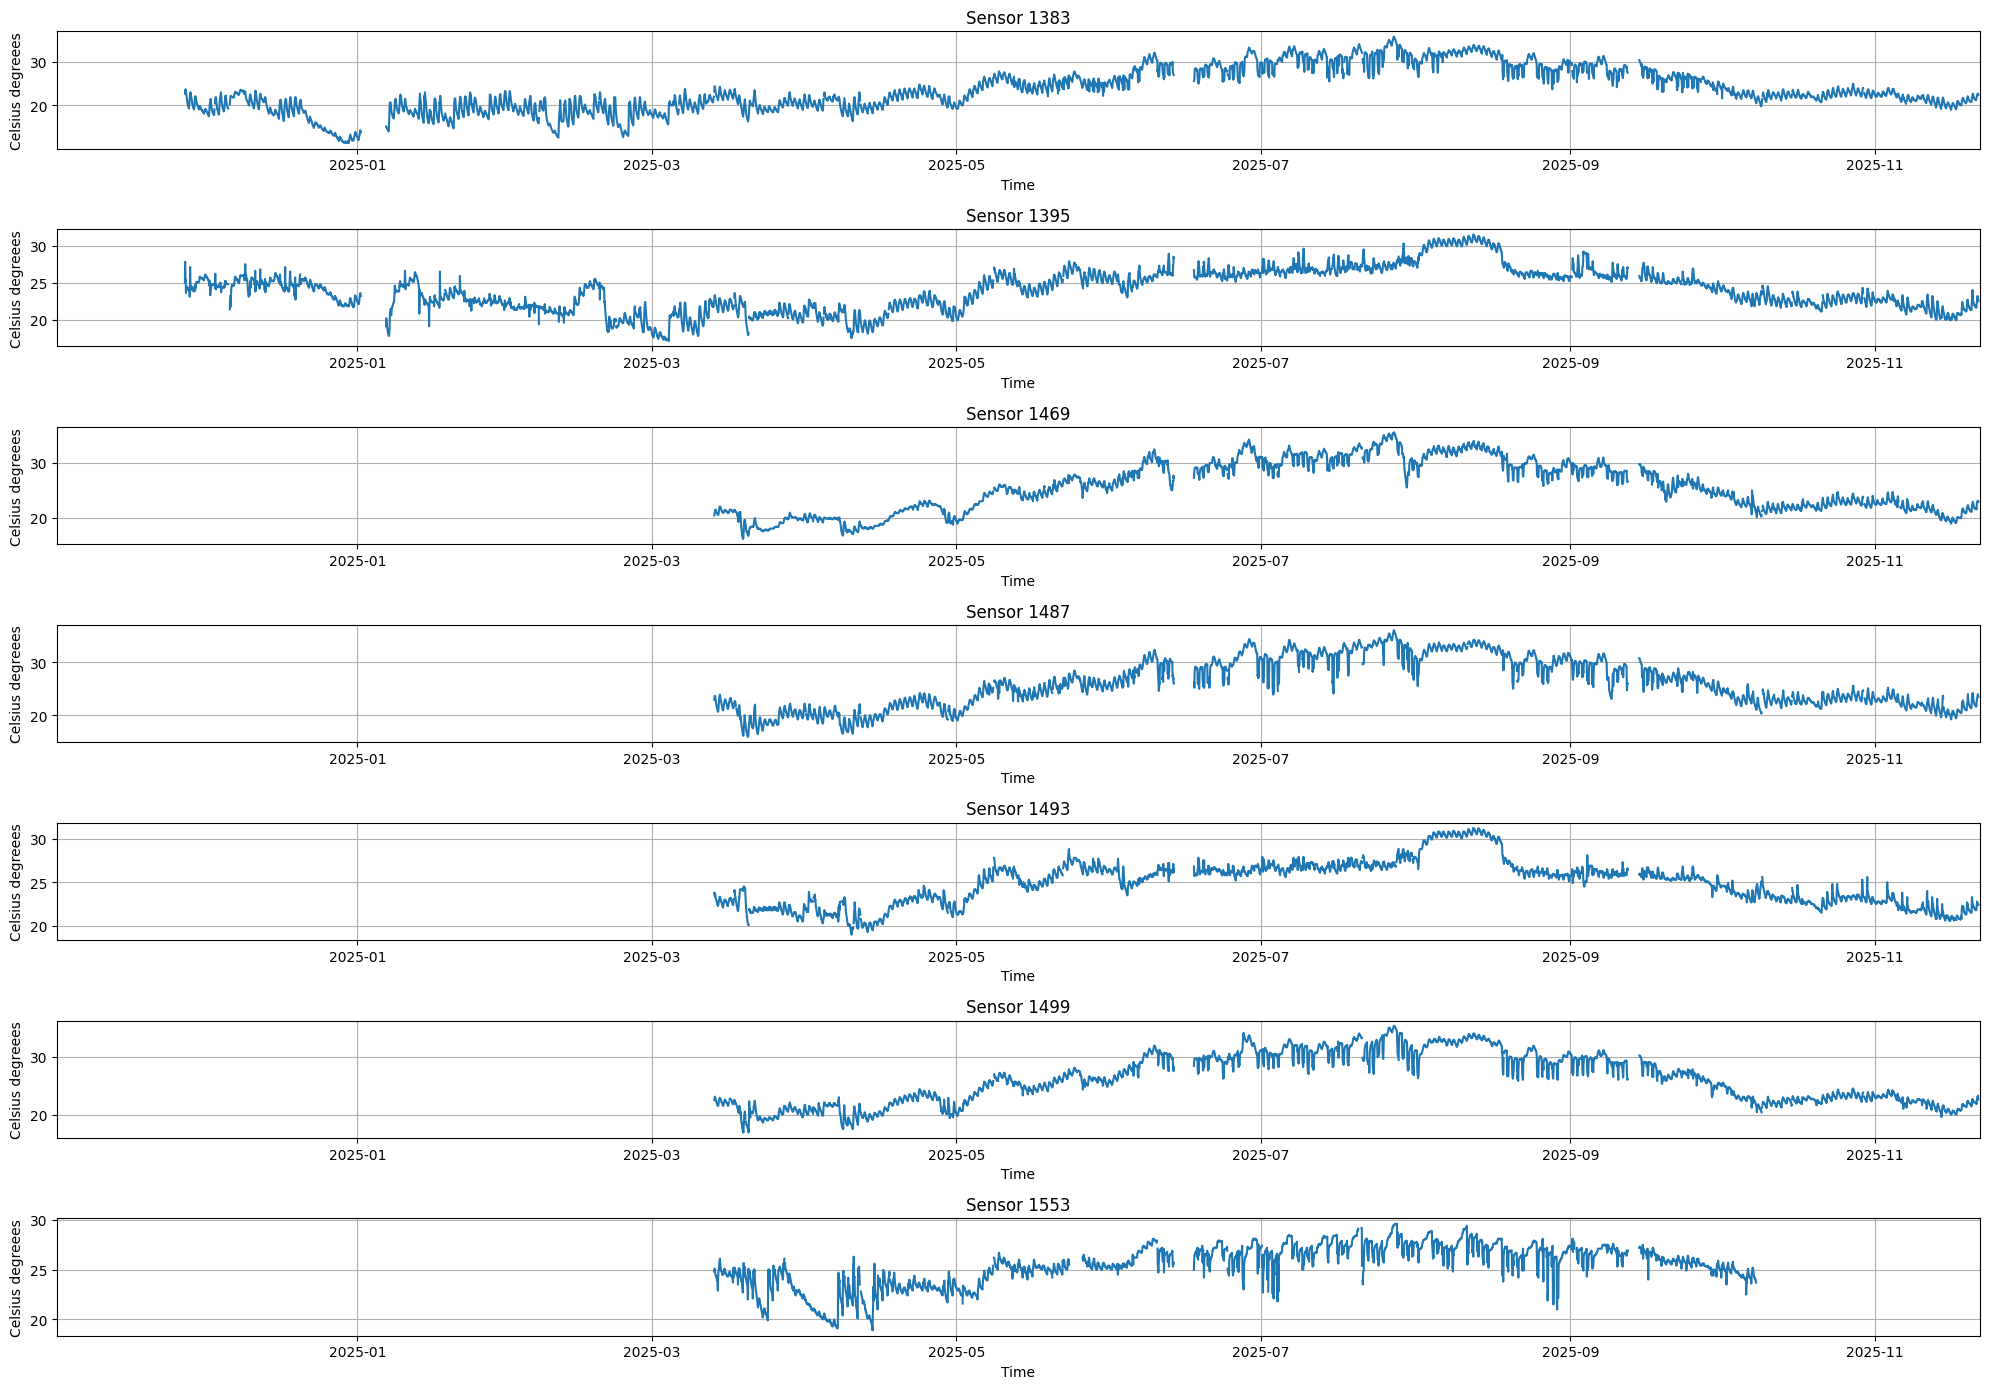

In [38]:
plt.figure(figsize=(20, 14))

for i in range (0,7):
  plt.subplot(7, 1, i+1)
  plt.plot(temperatures.index, temperatures[f'sensor{sensor_ids[i]}'])
  plt.title(f"Sensor {sensor_ids[i]}")
  plt.xlabel("Time")
  plt.ylabel("Celsius degreees")
  plt.grid(True)
  plt.xlim(pd.to_datetime('2024-11-01 19:00:00'), pd.to_datetime('2025-11-22 01:00:00'))

plt.tight_layout()
plt.show()

In [39]:
def missing_value_summary(df, columns):
    rows = []
    for col in columns:
        series = df[col]
        valid = series.dropna()

        if valid.empty:
            rows.append({'column': col, 'start': None, 'end': None, 'length': 0, 'missing': 0, 'missing_pct': 0.0})
            continue

        start = valid.index.min()
        end = valid.index.max()
        window = series.loc[start:end]
        length = len(window)
        missing = int(window.isna().sum())
        missing_pct = round((missing / length) * 100, 2) if length > 0 else 0.0

        rows.append({'column': col, 'start': start, 'end': end, 'length': length, 'missing': missing, 'missing_pct': missing_pct})

    return pd.DataFrame(rows).set_index('column')

sensor_columns = [f'sensor{sid}' for sid in sensor_ids]
sensor_summary = missing_value_summary(temperatures, sensor_columns)
sensor_summary

,start,end,length,missing,missing_pct
column,,,,,
sensor1383,2024-11-27 11:00:00,2025-11-21 17:00:00,8623,324,3.76
sensor1395,2024-11-27 11:00:00,2025-11-21 17:00:00,8623,340,3.94
sensor1469,2025-03-13 12:00:00,2025-11-21 17:00:00,6078,201,3.31
sensor1487,2025-03-13 12:00:00,2025-11-21 17:00:00,6078,224,3.69
sensor1493,2025-03-13 12:00:00,2025-11-21 17:00:00,6078,217,3.57
sensor1499,2025-03-13 12:00:00,2025-11-21 17:00:00,6078,224,3.69
sensor1553,2025-03-13 12:00:00,2025-10-08 05:00:00,5010,317,6.33


In [40]:
temperatures = temperatures.drop(columns=f'sensor1553')

temperatures['office12'] = temperatures[['sensor1469', 'sensor1499']].mean(axis=1, skipna=True)
temperatures['office35'] = temperatures[['sensor1383', 'sensor1487']].mean(axis=1, skipna=True)
temperatures['office67'] = temperatures[['sensor1395', 'sensor1493']].mean(axis=1, skipna=True)

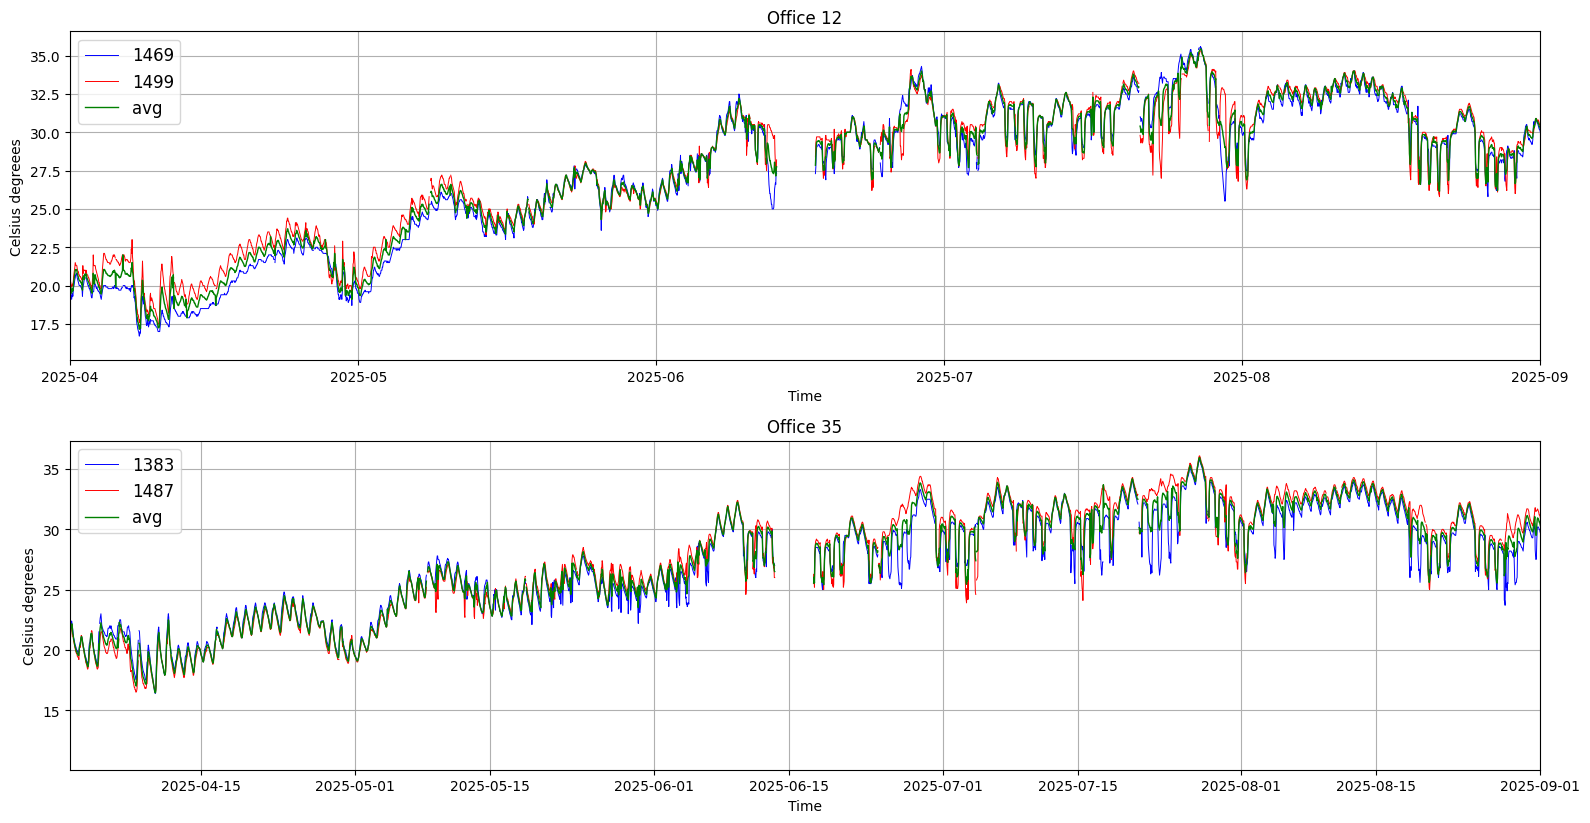

In [41]:
plt.figure(figsize=(16, 12))

plt.subplot(3, 1, 1)
plt.plot(temperatures.index, temperatures['sensor1469'], color='blue', linewidth=0.7)
plt.plot(temperatures.index, temperatures['sensor1499'], color='red', linewidth=0.7)
plt.plot(temperatures.index, temperatures['office12'], color='green', linewidth=1)
plt.title("Office 12")
plt.xlabel("Time")
plt.ylabel("Celsius degreees")
plt.grid(True)
plt.legend(['1469', '1499','avg'], loc='upper left', fontsize='large')
plt.xlim(pd.to_datetime('2025-04-01 00:00:00'), pd.to_datetime('2025-09-01 00:00:00'))

plt.subplot(3, 1, 2)
plt.plot(temperatures.index, temperatures['sensor1383'], color='blue', linewidth=0.7)
plt.plot(temperatures.index, temperatures['sensor1487'], color='red', linewidth=0.7)
plt.plot(temperatures.index, temperatures['office35'], color='green', linewidth=1)
plt.title("Office 35")
plt.xlabel("Time")
plt.ylabel("Celsius degreees")
plt.grid(True)
plt.legend(['1383', '1487','avg'], loc='upper left', fontsize='large')
plt.xlim(pd.to_datetime('2025-04-01 09:00:00'), pd.to_datetime('2025-09-01 00:00:00'))

plt.tight_layout()
plt.show()

In [42]:
for i in range (0,6):
  temperatures = temperatures.drop(columns=f'sensor{sensor_ids[i]}')
temperatures.head()

,office12,office35,office67
2024-11-27 11:00:00,NaN,22.7,25.0
2024-11-27 12:00:00,NaN,23.2,27.8
2024-11-27 13:00:00,NaN,23.5,26.3
2024-11-27 14:00:00,NaN,23.7,25.2
2024-11-27 15:00:00,NaN,23.6,25.4


In [43]:
office_columns = ['office12', 'office35', 'office67']
office_summary = missing_value_summary(temperatures, office_columns)
office_summary

,start,end,length,missing,missing_pct
column,,,,,
office12,2025-03-13 12:00:00,2025-11-21 17:00:00,6078,172,2.83
office35,2024-11-27 11:00:00,2025-11-21 17:00:00,8623,305,3.54
office67,2024-11-27 11:00:00,2025-11-21 17:00:00,8623,310,3.60


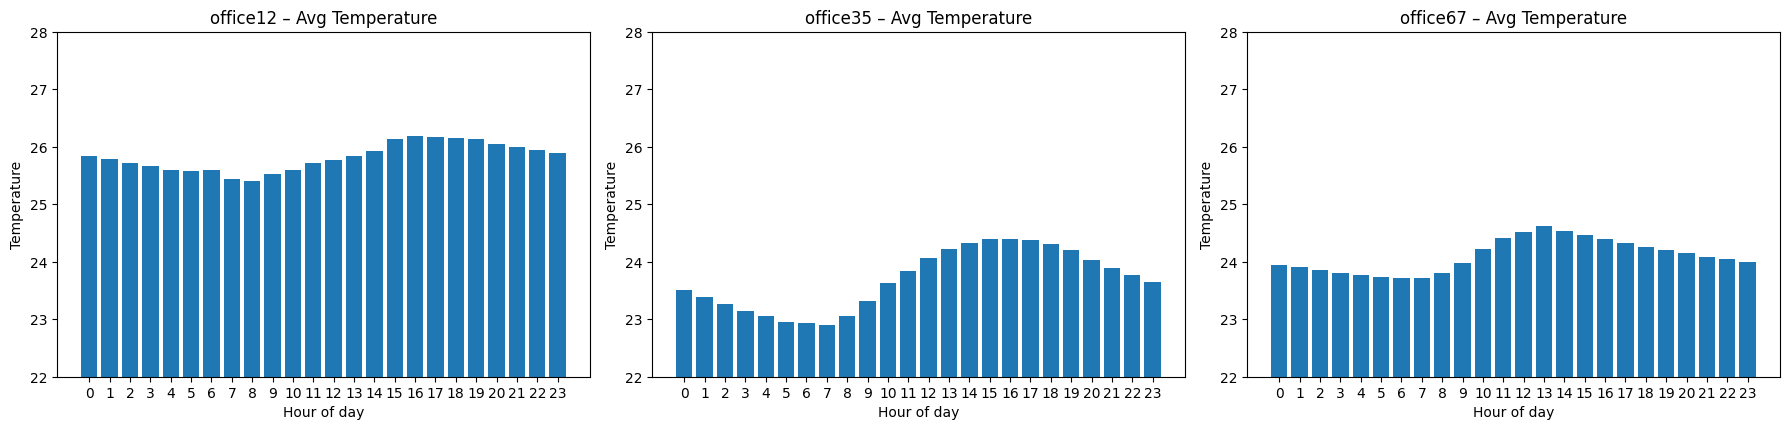

In [44]:
rooms = ['office12', 'office35', 'office67']
plt.figure(figsize=(18, 8))

for i, room in enumerate(rooms):
    temp = temperatures[f"{room}"]
    hourly_temp_mean = temp.groupby(temp.index.hour).mean()

    # Temperature
    plt.subplot(2, 3, i + 1)
    plt.bar(hourly_temp_mean.index, hourly_temp_mean.values)
    plt.xticks(range(24))
    plt.xlabel("Hour of day")
    plt.ylabel("Temperature")
    plt.ylim(22, 28)
    plt.title(f"{room} – Avg Temperature")

plt.tight_layout()
plt.show()


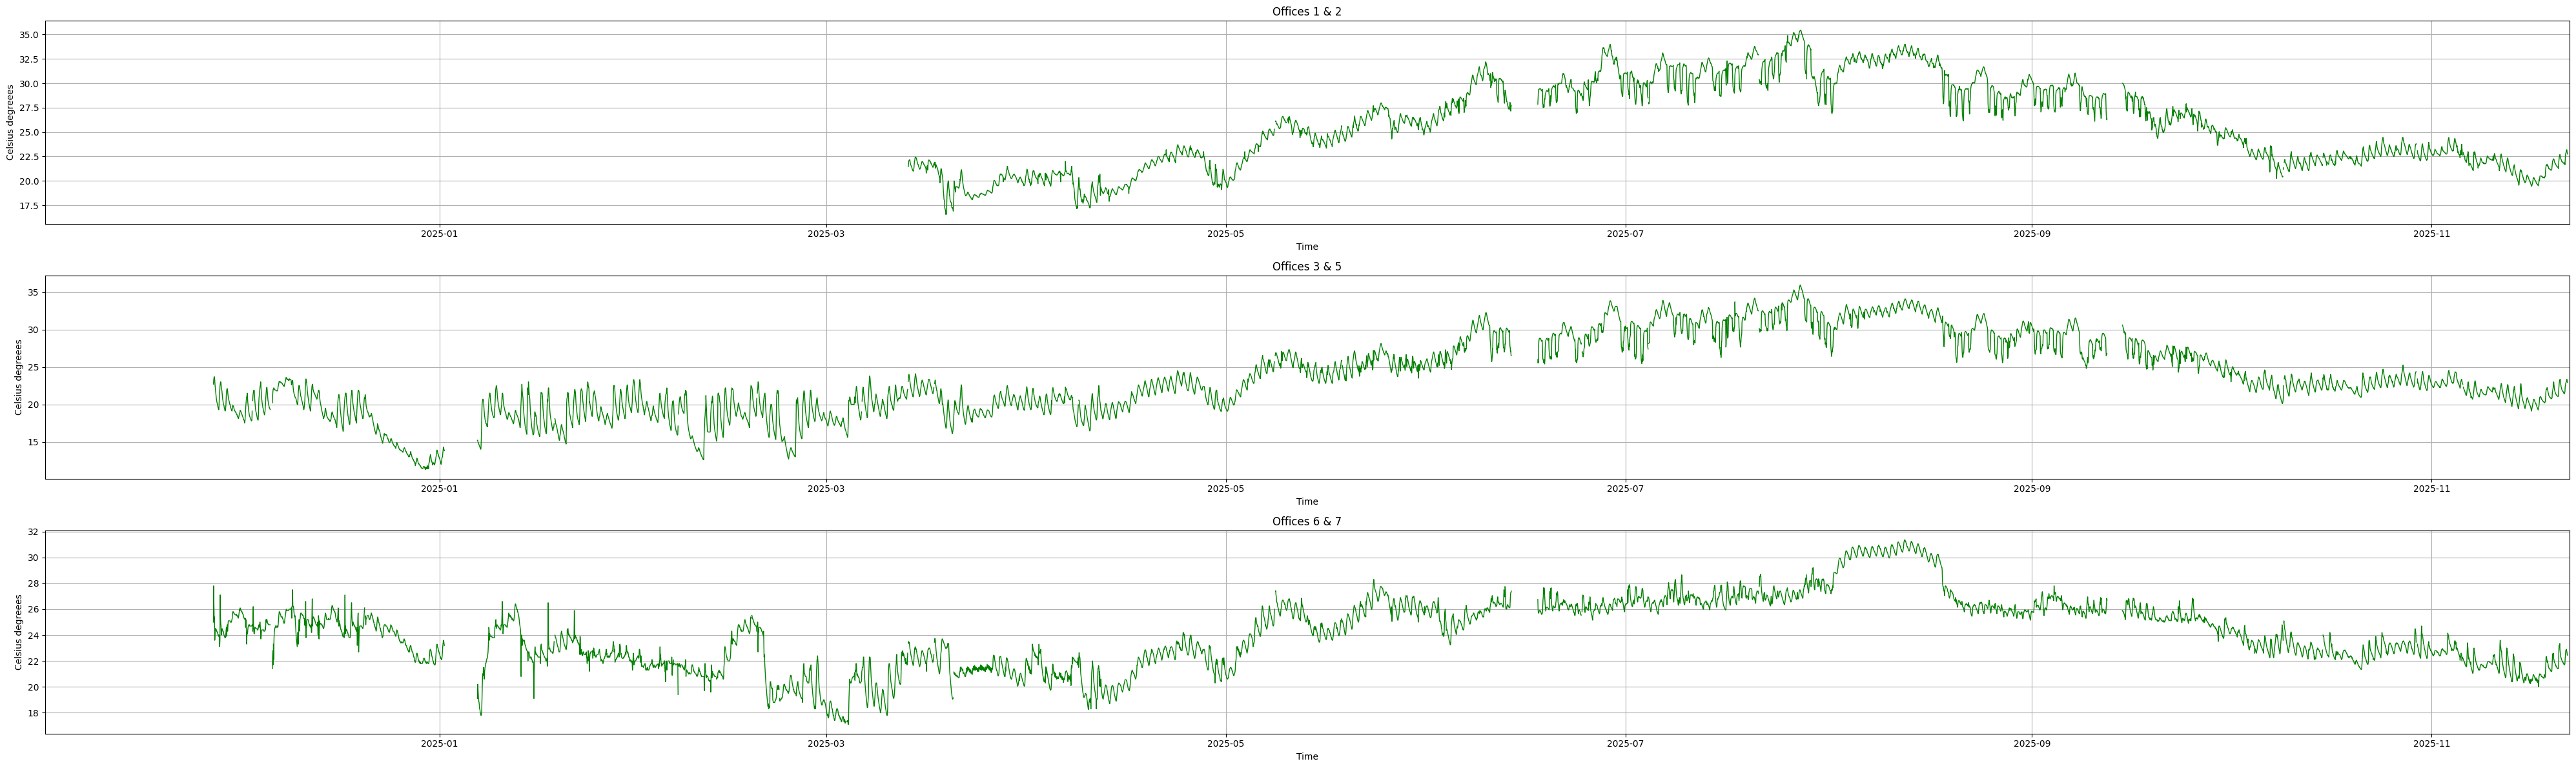

In [45]:
plt.figure(figsize=(40, 12))

plt.subplot(3, 1, 1)
plt.plot(temperatures.index, temperatures['office12'], color='green', linewidth=1)
plt.title("Offices 1 & 2")
plt.xlabel("Time")
plt.ylabel("Celsius degreees")
plt.grid(True)
plt.xlim(pd.to_datetime('2024-11-01 19:00:00'), pd.to_datetime('2025-11-22 01:00:00'))

plt.subplot(3, 1, 2)
plt.plot(temperatures.index, temperatures['office35'], color='green', linewidth=1)
plt.title("Offices 3 & 5")
plt.xlabel("Time")
plt.ylabel("Celsius degreees")
plt.grid(True)
plt.xlim(pd.to_datetime('2024-11-01 19:00:00'), pd.to_datetime('2025-11-22 01:00:00'))

plt.subplot(3, 1, 3)
plt.plot(temperatures.index, temperatures['office67'], color='green', linewidth=1)
plt.title("Offices 6 & 7")
plt.xlabel("Time")
plt.ylabel("Celsius degreees")
plt.grid(True)
plt.xlim(pd.to_datetime('2024-11-01 19:00:00'), pd.to_datetime('2025-11-22 01:00:00'))

plt.tight_layout()
plt.show()

In [46]:
monthly_table = temperatures['office12'].groupby(pd.Grouper(freq="ME")).describe()
monthly_table.index = monthly_table.index.strftime("%Y-%m")
monthly_table

,count,mean,std,min,25%,50%,75%,max
2024-11,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-12,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-01,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-02,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-03,443.0,19.987359,1.328813,16.55,18.800,20.100,21.125,22.45
2025-04,720.0,20.625000,1.557098,17.15,19.450,20.625,22.000,23.70
2025-05,740.0,24.911791,1.768817,19.35,24.150,25.200,26.150,28.00
2025-06,623.0,29.475923,1.836213,25.00,28.175,29.450,30.600,34.00
2025-07,739.0,31.364885,1.696216,27.70,30.125,31.350,32.350,35.45
2025-08,744.0,30.966331,1.929537,26.15,29.450,31.500,32.600,34.00


In [47]:
monthly_table = temperatures['office35'].groupby(pd.Grouper(freq="ME")).describe()
monthly_table.index = monthly_table.index.strftime("%Y-%m")
monthly_table

,count,mean,std,min,25%,50%,75%,max
2024-11,85.0,20.603529,1.360536,18.70,19.5000,20.200,21.70,23.70
2024-12,735.0,18.054150,3.457556,11.30,15.1000,18.600,20.90,23.60
2025-01,622.0,18.813183,2.188291,12.00,17.5000,18.700,20.40,23.30
2025-02,669.0,18.152167,2.376403,12.60,16.5000,18.500,19.90,23.00
2025-03,741.0,20.045209,1.730810,15.60,18.7500,20.050,21.30,24.10
2025-04,718.0,20.842897,1.686028,16.45,19.6000,20.850,22.15,24.50
2025-05,741.0,24.743860,1.680062,19.10,23.9500,25.000,25.85,28.15
2025-06,623.0,28.853531,2.106775,24.30,27.1500,28.850,30.25,33.85
2025-07,739.0,31.408322,1.915355,25.45,30.2500,31.600,32.60,35.95
2025-08,744.0,30.968212,1.955069,25.55,29.6375,31.425,32.55,34.10


# Συμπλήρωση κενών τιμών



In [48]:
def gap_length_distribution(series, label=None):
    """Table of consecutive-NaN gap lengths (in hours) for a series, printed before it gets filled."""
    is_na = series.isna()
    gap_id = (is_na != is_na.shift()).cumsum()
    gap_lengths = is_na.groupby(gap_id).sum()
    gap_lengths = gap_lengths[gap_lengths > 0].astype(int)

    if label:
        print(f"--- Gap length distribution: {label} ---")
    if gap_lengths.empty:
        print("No gaps found.")
        return pd.DataFrame(columns=['gap_length_hours', 'num_gaps']).set_index('gap_length_hours')

    counts = gap_lengths.value_counts().sort_index()
    print(f"Total gaps: {len(gap_lengths)}, total missing hours: {int(gap_lengths.sum())}")
    for length, count in counts.items():
        hour_word = 'hour' if length == 1 else 'hours'
        print(f"  {count} gap(s) of {length} {hour_word}")

    table = counts.rename('num_gaps').rename_axis('gap_length_hours').to_frame()
    return table

### Office 12

In [49]:
y = temperatures['office12'][temperatures.index > '2025-03-13 11:00:00']
print(y.isna().sum())

nan_indices = y[y.isna()].index

if not nan_indices.empty:
    print(f"First NaN index: {nan_indices.min()}")
    print(f"Last NaN index: {nan_indices.max()}")
else:
    print("No NaN values found in y.")

172
First NaN index: 2025-03-17 11:00:00
Last NaN index: 2025-11-05 19:00:00


In [50]:
gap_length_distribution(temperatures['office12'][temperatures.index > '2025-03-13 11:00:00'], label='Office 12')

--- Gap length distribution: Office 12 ---
Total gaps: 15, total missing hours: 172
  8 gap(s) of 1 hour
  3 gap(s) of 2 hours
  1 gap(s) of 3 hours
  1 gap(s) of 4 hours
  1 gap(s) of 55 hours
  1 gap(s) of 96 hours


,num_gaps
gap_length_hours,
1,8
2,3
3,1
4,1
55,1
96,1


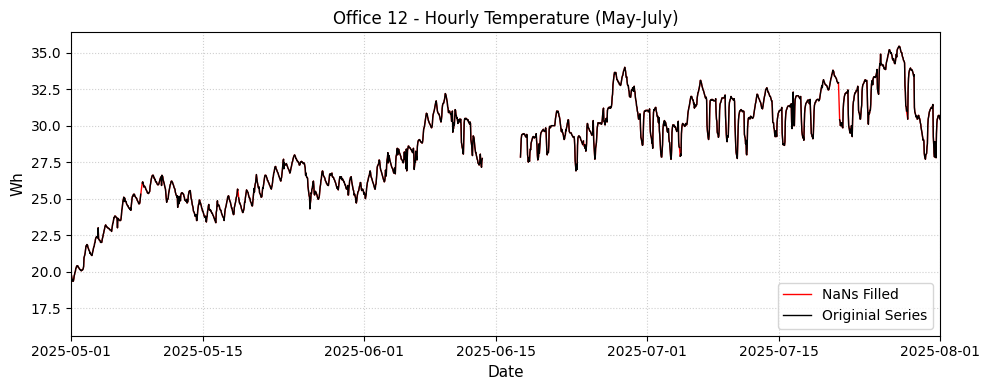

In [51]:
temperatures['office12_partially_filled'] = temperatures['office12']

interpolation_mask = ~((temperatures.index >= '2025-06-13') & (temperatures.index <= '2025-06-18') | (temperatures.index >= '2025-09-12') & (temperatures.index <= '2025-09-15'))

temperatures.loc[interpolation_mask, 'office12_partially_filled'] = temperatures.loc[interpolation_mask, 'office12_partially_filled'].interpolate(method = 'time')

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(temperatures.index, temperatures['office12_partially_filled'], color='r', linewidth=1, label = 'NaNs Filled')
ax.plot(temperatures.index, temperatures['office12'], color='black', linewidth=1, label = 'Originial Series')
ax.set_title("Office 12 - Hourly Temperature (May-July)")
ax.set_xlabel("Date", fontsize=11)
ax.set_ylabel("Wh", fontsize=11)
ax.set_xlim(pd.to_datetime('2025-05-01'),pd.to_datetime('2025-08-01'))

ax.legend(loc='lower right', fontsize=10, frameon=True)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


In [52]:
y = temperatures['office12_partially_filled'] [temperatures.index > '2025-03-13 11:00:00']
print(y.isna().sum())

nan_indices = y[y.isna()].index

if not nan_indices.empty:
    print(f"First NaN index: {nan_indices.min()}")
    print(f"Last NaN index: {nan_indices.max()}")
else:
    print("No NaN values found in y.")

151
First NaN index: 2025-06-13 14:00:00
Last NaN index: 2025-09-14 18:00:00


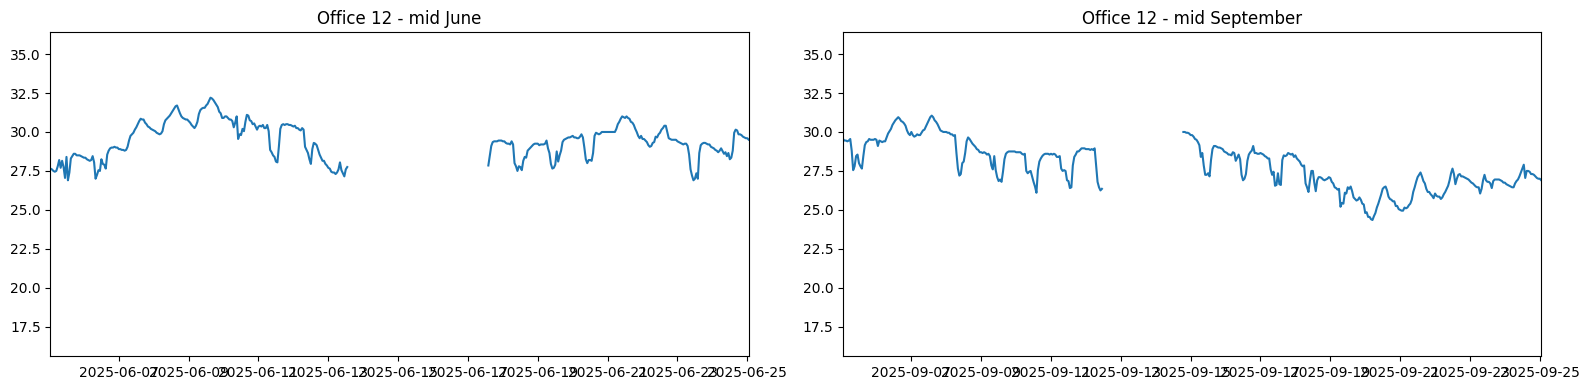

In [53]:
plt.figure(figsize=(16, 4))

plt.subplot(1,2,1)
plt.plot(temperatures.index,temperatures['office12_partially_filled'])
plt.xlim(pd.to_datetime('2025-06-05 01:00:00'), pd.to_datetime('2025-06-25 01:00:00'))
plt.title('Office 12 - mid June')

plt.subplot(1,2,2)
plt.plot(temperatures.index,temperatures['office12_partially_filled'])
plt.xlim(pd.to_datetime('2025-09-05 01:00:00'), pd.to_datetime('2025-09-25 01:00:00'))
plt.title('Office 12 - mid September')

plt.tight_layout()
plt.show()

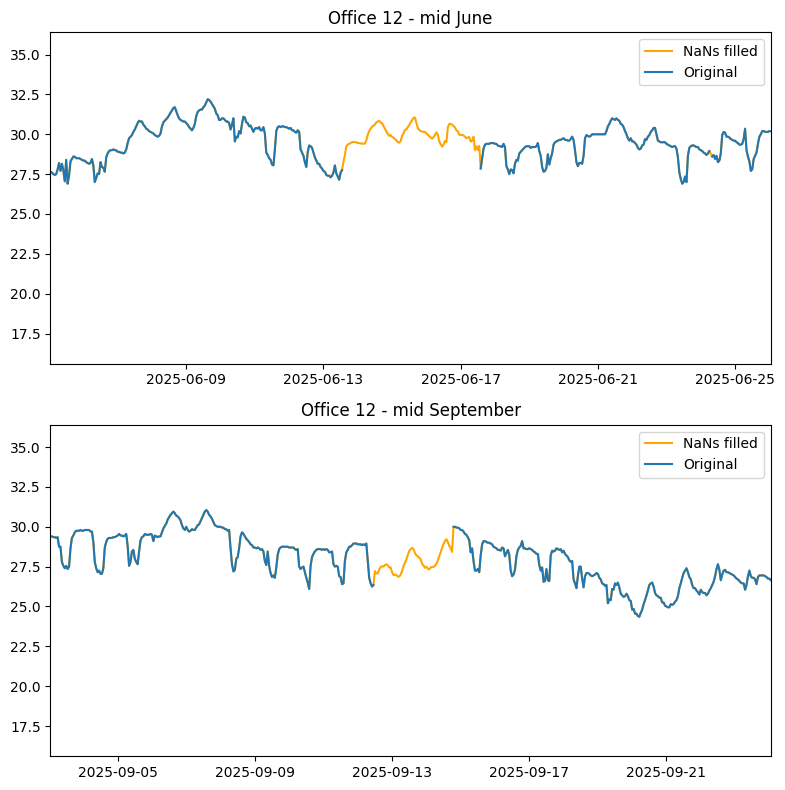

In [54]:
mask = temperatures['office12_partially_filled'].isna() & ((temperatures.index.month == 6) | (temperatures.index.month == 9))
temperatures.loc[mask, 'office12_partially_filled'] = (temperatures['office12_partially_filled'].shift(7*24)[mask] + temperatures['office12_partially_filled'].shift(-7*24)[mask]) / 2

plt.figure(figsize=(8, 8))

plt.subplot(2,1,1)
plt.plot(temperatures.index,temperatures['office12_partially_filled'], label = 'NaNs filled', color = 'orange')
plt.plot(temperatures.index,temperatures['office12'], label = 'Original')
plt.xlim(pd.to_datetime('2025-06-05 01:00:00'), pd.to_datetime('2025-06-26 01:00:00'))
plt.title('Office 12 - mid June')
plt.legend(loc='best')

plt.subplot(2,1,2)
plt.plot(temperatures.index,temperatures['office12_partially_filled'], label = 'NaNs filled', color = 'orange')
plt.plot(temperatures.index,temperatures['office12'], label = 'Original')
plt.xlim(pd.to_datetime('2025-09-03 01:00:00'), pd.to_datetime('2025-09-24 01:00:00'))
plt.title('Office 12 - mid September')
plt.legend(loc='best')

plt.tight_layout()
plt.show()

### Office 35

In [55]:
print(temperatures['office35'].isna().sum())
nan_indices = temperatures['office35'][temperatures['office35'].isna()].index
if not nan_indices.empty:
    print(f"First NaN index: {nan_indices.min()}")
    print(f"Last NaN index: {nan_indices.max()}")
else:
    print("No NaN values found in y.")

305
First NaN index: 2024-12-03 10:00:00
Last NaN index: 2025-11-05 19:00:00


In [56]:
gap_length_distribution(temperatures['office35'], label='Office 35')

--- Gap length distribution: Office 35 ---
Total gaps: 24, total missing hours: 305
  15 gap(s) of 1 hour
  4 gap(s) of 2 hours
  1 gap(s) of 4 hours
  1 gap(s) of 7 hours
  1 gap(s) of 55 hours
  1 gap(s) of 96 hours
  1 gap(s) of 120 hours


,num_gaps
gap_length_hours,
1,15
2,4
4,1
7,1
55,1
96,1
120,1


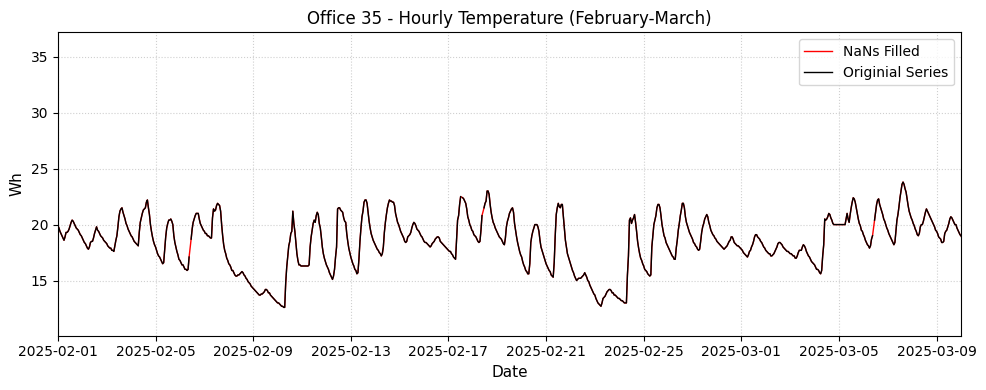

In [57]:
temperatures['office35_partially_filled'] = temperatures['office35']
interpolation_mask = ~(((temperatures.index >= '2025-01-01') & (temperatures.index <= '2025-01-07')) | ((temperatures.index >= '2025-06-13') & (temperatures.index <= '2025-06-18')) | ((temperatures.index >= '2025-09-12') & (temperatures.index <= '2025-09-15')))
#01-01 until 07-01 # 13-06 until 18-06 # 12 -09 until 15-09

temperatures.loc[interpolation_mask, 'office35_partially_filled'] = temperatures.loc[interpolation_mask, 'office35_partially_filled'].interpolate(method = 'time')

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(temperatures.index, temperatures['office35_partially_filled'], color='r', linewidth=1, label = 'NaNs Filled')
ax.plot(temperatures.index, temperatures['office35'], color='black', linewidth=1, label = 'Originial Series')
ax.set_title("Office 35 - Hourly Temperature (February-March)")
ax.set_xlabel("Date", fontsize=11)
ax.set_ylabel("Wh", fontsize=11)
ax.set_xlim(pd.to_datetime('2025-02-01'),pd.to_datetime('2025-03-10'))

ax.legend(loc='upper right', fontsize=10, frameon=True)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [58]:
print(temperatures['office35_partially_filled'].isna().sum())
nan_indices = temperatures['office35_partially_filled'][temperatures['office35_partially_filled'].isna()].index

if not nan_indices.empty:
    print(f"First NaN index: {nan_indices.min()}")
    print(f"Last NaN index: {nan_indices.max()}")
else:
    print("No NaN values found in y.")

271
First NaN index: 2025-01-01 18:00:00
Last NaN index: 2025-09-14 18:00:00


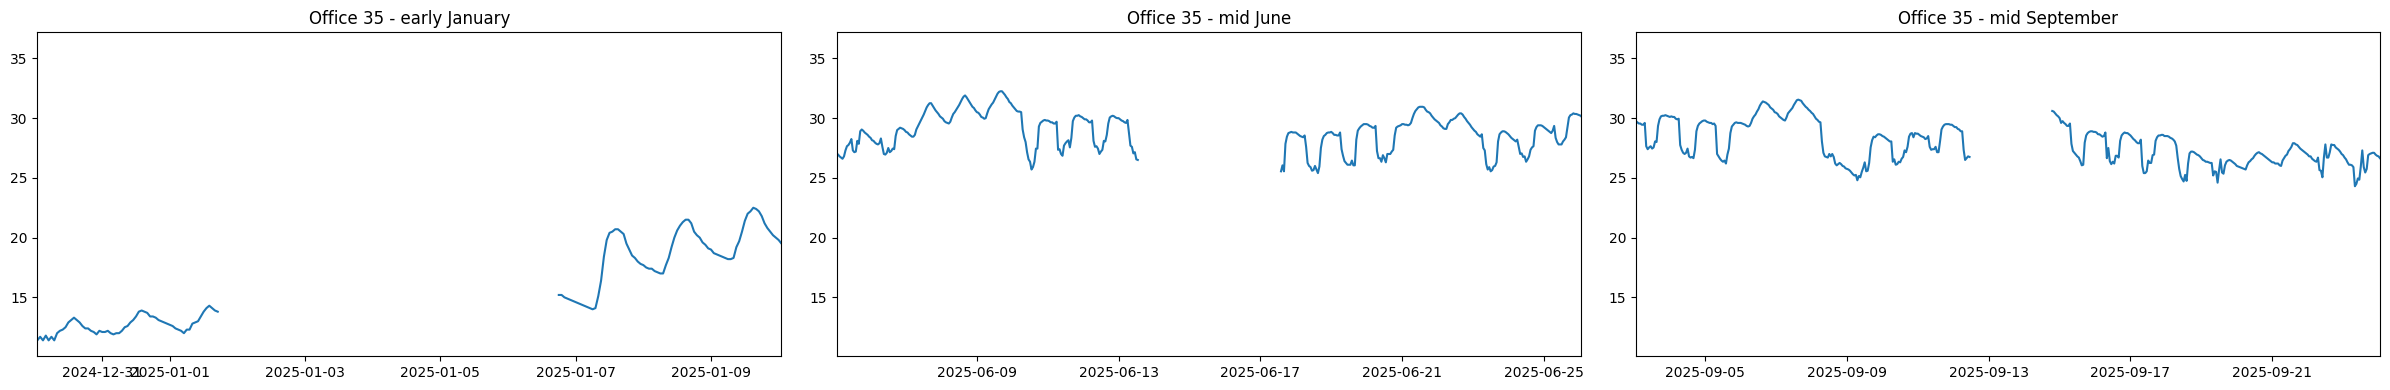

In [59]:
plt.figure(figsize=(24, 4))

plt.subplot(1,3,1)
plt.plot(temperatures.index,temperatures['office35_partially_filled'])
plt.xlim(pd.to_datetime('2024-12-30 01:00:00'), pd.to_datetime('2025-01-10 01:00:00'))
plt.title('Office 35 - early January')

plt.subplot(1,3,2)
plt.plot(temperatures.index,temperatures['office35_partially_filled'])
plt.xlim(pd.to_datetime('2025-06-05 01:00:00'), pd.to_datetime('2025-06-26 01:00:00'))
plt.title('Office 35 - mid June')

plt.subplot(1,3,3)
plt.plot(temperatures.index,temperatures['office35_partially_filled'])
plt.xlim(pd.to_datetime('2025-09-03 01:00:00'), pd.to_datetime('2025-09-24 01:00:00'))
plt.title('Office 35 - mid September')

plt.tight_layout()
plt.show()

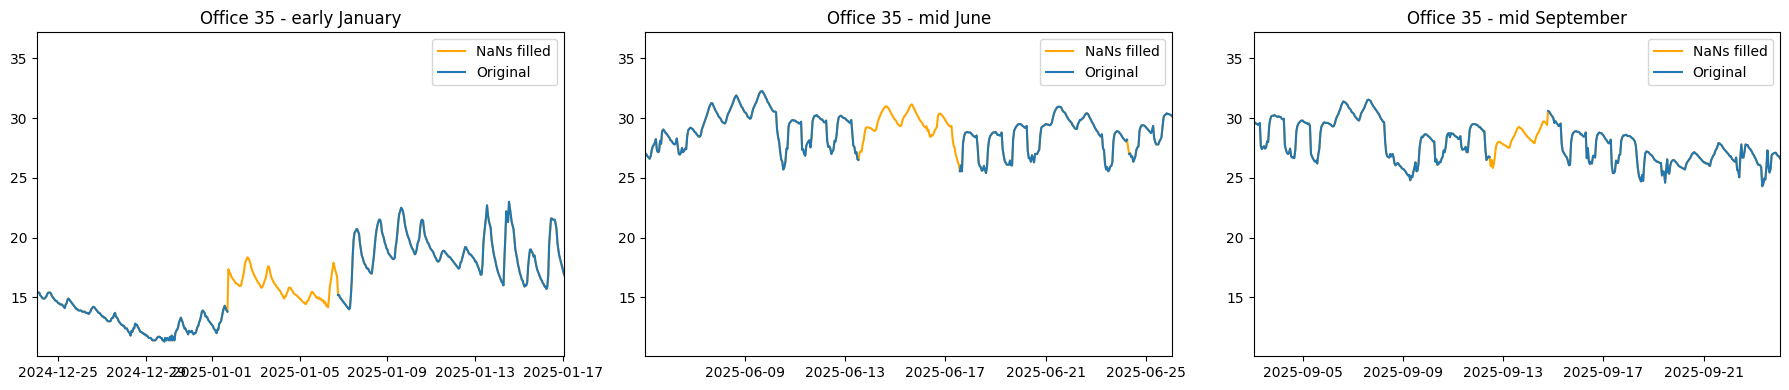

In [60]:
mask = temperatures['office35_partially_filled'].isna() & ((temperatures.index >= '2025-01-01') & (temperatures.index <= '2025-07-01') | (temperatures.index >= '2025-06-13') & (temperatures.index <= '2025-06-18') | (temperatures.index >= '2025-09-12') & (temperatures.index <= '2025-09-15'))
temperatures.loc[mask, 'office35_partially_filled'] = (temperatures['office35_partially_filled'].shift(7*24)[mask] + temperatures['office35_partially_filled'].shift(-7*24)[mask]) / 2

plt.figure(figsize=(18, 4))

plt.subplot(1,3,1)
plt.plot(temperatures.index,temperatures['office35_partially_filled'], color = 'orange', label = 'NaNs filled')
plt.plot(temperatures.index,temperatures['office35'], label = 'Original')
plt.xlim(pd.to_datetime('2024-12-24 01:00:00'), pd.to_datetime('2025-01-17 01:00:00'))
plt.title('Office 35 - early January')
plt.legend(loc='best')

plt.subplot(1,3,2)
plt.plot(temperatures.index,temperatures['office35_partially_filled'], color = 'orange', label = 'NaNs filled')
plt.plot(temperatures.index,temperatures['office35'], label = 'Original')
plt.xlim(pd.to_datetime('2025-06-05 01:00:00'), pd.to_datetime('2025-06-26 01:00:00'))
plt.title('Office 35 - mid June')
plt.legend(loc='best')

plt.subplot(1,3,3)
plt.plot(temperatures.index,temperatures['office35_partially_filled'], color = 'orange', label = 'NaNs filled')
plt.plot(temperatures.index,temperatures['office35'], label = 'Original')
plt.xlim(pd.to_datetime('2025-09-03 01:00:00'), pd.to_datetime('2025-09-24 01:00:00'))
plt.title('Office 35 - mid September')
plt.legend(loc='best')

plt.tight_layout()
plt.show()

(481248.0, 490008.0)

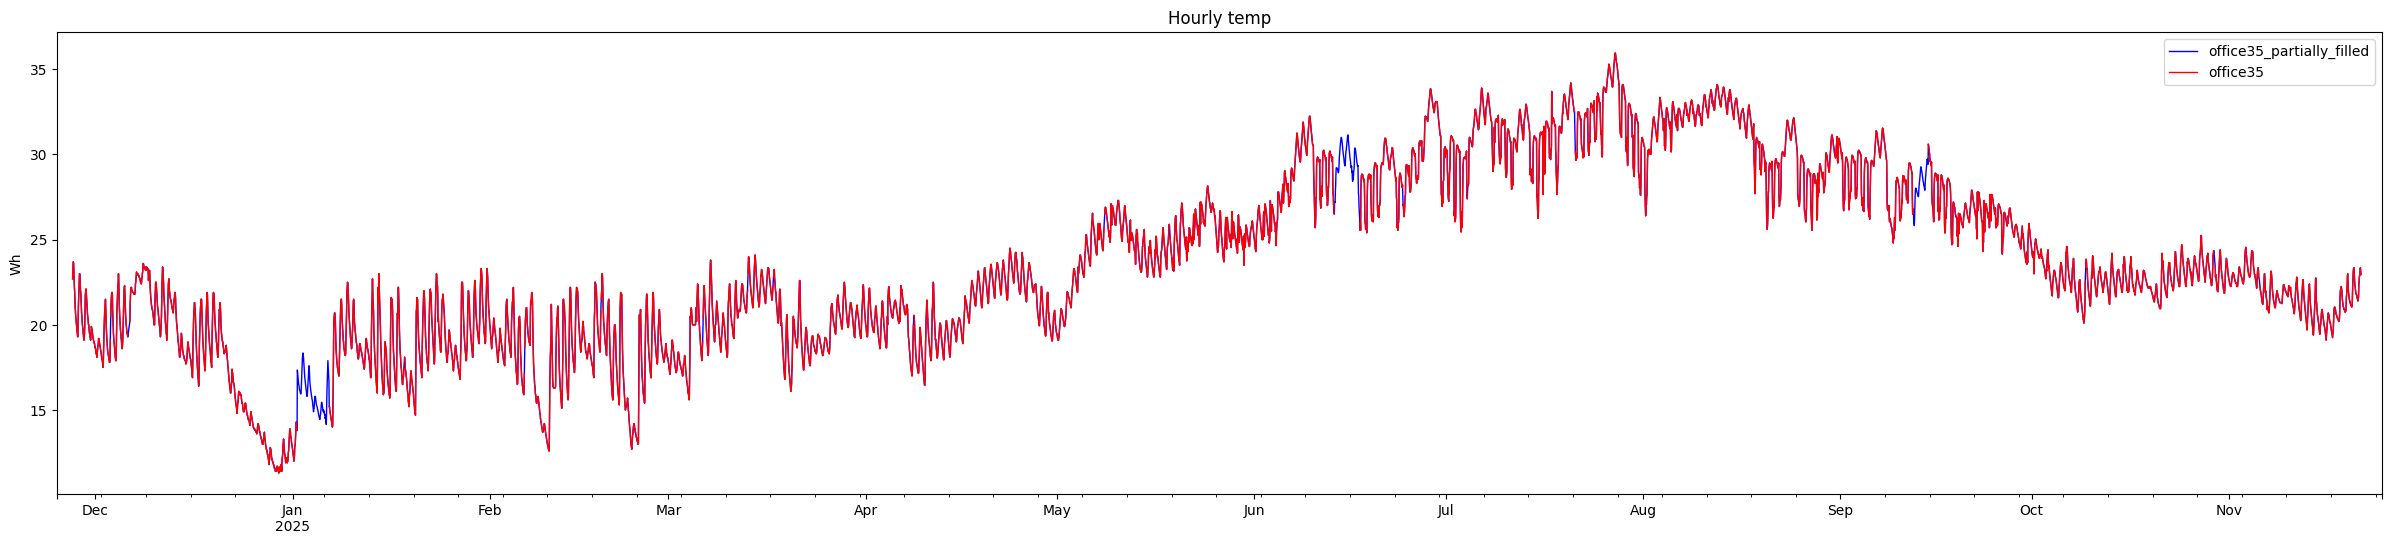

In [61]:
fig = plt.figure()
ax = plt.subplot(111)
temperatures.plot(y='office35_partially_filled', title = "Hourly temp", color='b', linewidth=1, figsize=(30, 6) ,ylabel= "Wh",ax=ax)
temperatures.plot(y='office35', title = "Hourly temp", color='r', linewidth=1, figsize=(30, 6) ,ylabel= "Wh",ax=ax)
ax.set_xlim(pd.to_datetime('2024-11-25'),pd.to_datetime('2025-11-25'))
#ax.set_xlim(pd.to_datetime('2025-06-24 01:00:00'),pd.to_datetime('2025-06-24 12:00:00'))


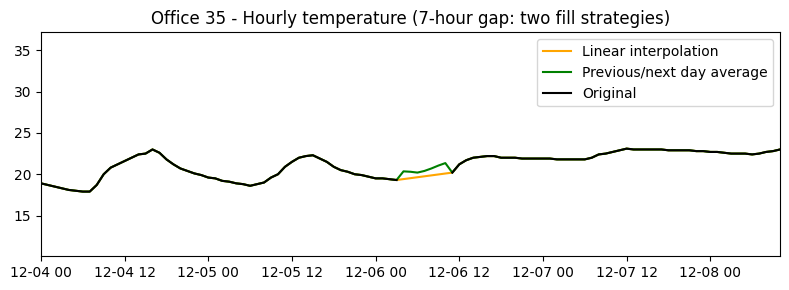

In [62]:

gap_start, gap_end = '2024-12-06 04:00:00', '2024-12-06 10:00:00'
gap_mask = (temperatures.index >= gap_start) & (temperatures.index <= gap_end)

temperatures['office35_daily_avg_filled'] = temperatures['office35']
temperatures.loc[gap_mask, 'office35_daily_avg_filled'] = (
    temperatures['office35'].shift(24)[gap_mask] + temperatures['office35'].shift(-24)[gap_mask]
) / 2

plt.figure(figsize=(8, 3))

plt.plot(temperatures.index, temperatures['office35_partially_filled'], color='orange', label='Linear interpolation')
plt.plot(temperatures.index, temperatures['office35_daily_avg_filled'], color='green', label='Previous/next day average')
plt.plot(temperatures.index, temperatures['office35'], color='black', label='Original')
plt.xlim(pd.to_datetime('2024-12-04 00:00:00'), pd.to_datetime('2024-12-08 10:00:00'))
plt.title('Office 35 - Hourly temperature (7-hour gap: two fill strategies)')
plt.legend(loc='best')
plt.tight_layout()
plt.show()

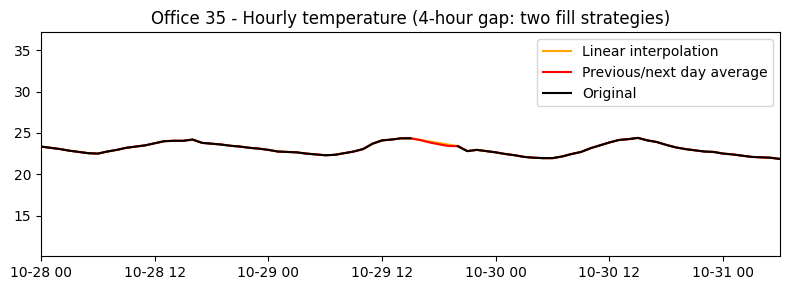

In [63]:

gap_start, gap_end = '2025-10-29 16:00:00', '2025-10-29 19:00:00'
gap_mask = (temperatures.index >= gap_start) & (temperatures.index <= gap_end)

temperatures['office35_daily_avg_filled_4h'] = temperatures['office35']
temperatures.loc[gap_mask, 'office35_daily_avg_filled_4h'] = (
    temperatures['office35'].shift(24)[gap_mask] + temperatures['office35'].shift(-24)[gap_mask]
) / 2

plt.figure(figsize=(8, 3))

plt.plot(temperatures.index, temperatures['office35_partially_filled'], color='orange', label='Linear interpolation')
plt.plot(temperatures.index, temperatures['office35_daily_avg_filled_4h'], color='red', label='Previous/next day average')
plt.plot(temperatures.index, temperatures['office35'], color='black', label='Original')
plt.xlim(pd.to_datetime('2025-10-28 00:00:00'), pd.to_datetime('2025-10-31 06:00:00'))
plt.title('Office 35 - Hourly temperature (4-hour gap: two fill strategies)')
plt.legend(loc='best')
plt.tight_layout()
plt.show()

### Save

In [72]:
temperatures.rename(columns = {'office12_partially_filled': 'o12_full', 'office35_partially_filled': 'o35_full', 'office67_partially_filled' : 'o67_full'}, inplace=True)
temperatures

,office12,office35,office67,o12_full,o35_full,office35_daily_avg_filled,office35_daily_avg_filled_4h
2024-11-27 11:00:00,NaN,22.70,25.00,NaN,22.70,22.70,22.70
2024-11-27 12:00:00,NaN,23.20,27.80,NaN,23.20,23.20,23.20
2024-11-27 13:00:00,NaN,23.50,26.30,NaN,23.50,23.50,23.50
2024-11-27 14:00:00,NaN,23.70,25.20,NaN,23.70,23.70,23.70
2024-11-27 15:00:00,NaN,23.60,25.40,NaN,23.60,23.60,23.60
...,...,...,...,...,...,...,...
2025-11-21 13:00:00,23.00,23.05,22.90,23.00,23.05,23.05,23.05
2025-11-21 14:00:00,23.15,23.15,22.80,23.15,23.15,23.15,23.15
2025-11-21 15:00:00,23.20,23.35,22.75,23.20,23.35,23.35,23.35
2025-11-21 16:00:00,23.00,23.15,22.60,23.00,23.15,23.15,23.15


In [73]:
temperatures[['o12_full', 'o35_full']] = temperatures[['o12_full', 'o35_full']].round(1)
temperatures.to_csv("../data/office_temps_combined_and_aligned.csv")


# Εξωτερικές θερμοκρασίες


In [74]:
import requests
import pandas as pd
import datetime
from datetime import timedelta

In [75]:
min_date = datetime.date(2024, 12, 1)
max_date = datetime.date(2025, 11, 19)


# --- 1) Ορισμός περιοχής & εύρους ημερομηνιών ---
latitude = 37.98   # Αθήνα (αλλάζεις για άλλη πόλη/χώρα)
longitude = 23.73
start_date = min_date.isoformat()
end_date   =  (max_date + timedelta(days=1)).isoformat()

# --- 2) Κάλεσμα στο Open-Meteo ARCHIVE (ιστορικά) σε UTC ---
url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": latitude,
    "longitude": longitude,
    "start_date": start_date,
    "end_date": end_date,
    "hourly": "temperature_2m",
    "timezone": "UTC",   # για να ταιριάζει 1-1 στο 'hour' σου
}

r = requests.get(url, params=params)
r.raise_for_status()
data = r.json()

df_tout = pd.DataFrame({
    "hour": pd.to_datetime(data["hourly"]["time"], utc=True),
    "T_out": data["hourly"]["temperature_2m"]
}).sort_values("hour")

In [76]:
df_tout

,hour,T_out
0,2024-12-01 00:00:00+00:00,13.9
1,2024-12-01 01:00:00+00:00,13.8
2,2024-12-01 02:00:00+00:00,14.3
3,2024-12-01 03:00:00+00:00,14.4
4,2024-12-01 04:00:00+00:00,13.7
...,...,...
8515,2025-11-20 19:00:00+00:00,19.3
8516,2025-11-20 20:00:00+00:00,19.0
8517,2025-11-20 21:00:00+00:00,18.9
8518,2025-11-20 22:00:00+00:00,18.8


In [77]:
url = "https://api.open-meteo.com/v1/forecast"

params = {
    "latitude": latitude,
    "longitude": longitude,
    "hourly": "temperature_2m",
    "timezone": "UTC"
}

r = requests.get(url, params=params)
r.raise_for_status()
data = r.json()

df_forecast = pd.DataFrame({
    "hour": pd.to_datetime(data["hourly"]["time"], utc=True),
    "T_out_forecast": data["hourly"]["temperature_2m"]
}).sort_values("hour")

df_forecast.head()
url = "https://api.open-meteo.com/v1/forecast"

params = {
    "latitude": latitude,
    "longitude": longitude,
    "hourly": "temperature_2m",
    "timezone": "UTC"
}

r = requests.get(url, params=params)
r.raise_for_status()
data = r.json()

df_forecast = pd.DataFrame({
    "hour": pd.to_datetime(data["hourly"]["time"], utc=True),
    "T_out_forecast": data["hourly"]["temperature_2m"]
}).sort_values("hour")

df_forecast

,hour,T_out_forecast
0,2026-10-28 00:00:00+00:00,12.4
1,2026-10-28 01:00:00+00:00,12.3
2,2026-10-28 02:00:00+00:00,12.3
3,2026-10-28 03:00:00+00:00,12.1
4,2026-10-28 04:00:00+00:00,12.1
...,...,...
163,2026-11-03 19:00:00+00:00,14.6
164,2026-11-03 20:00:00+00:00,14.1
165,2026-11-03 21:00:00+00:00,13.5
166,2026-11-03 22:00:00+00:00,12.9


(np.float64(20058.791666666668), np.float64(20439.041666666668))

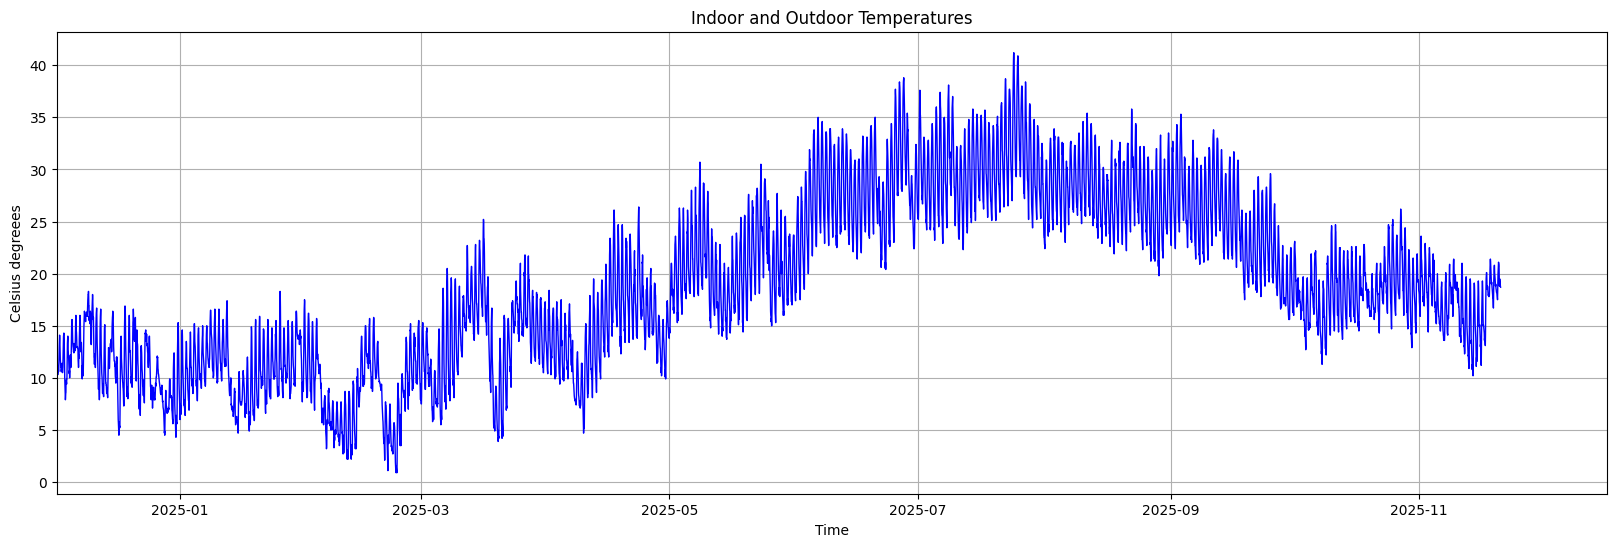

In [78]:
plt.figure(figsize=(20, 6))

plt.plot(df_forecast['hour'],df_forecast['T_out_forecast'], linewidth=1,color='red')
plt.plot(df_tout['hour'], df_tout['T_out'],  linewidth=1,color='blue')
plt.title("Indoor and Outdoor Temperatures")
plt.xlabel("Time")
plt.ylabel("Celsius degreees")
plt.grid(True)
#plt.legend(['office12','office35','office67','outdoor'])
plt.xlim(pd.to_datetime('2024-12-01 19:00:00'), pd.to_datetime('2025-12-17 01:00:00'))

(np.float64(20028.791666666668), np.float64(20414.041666666668))

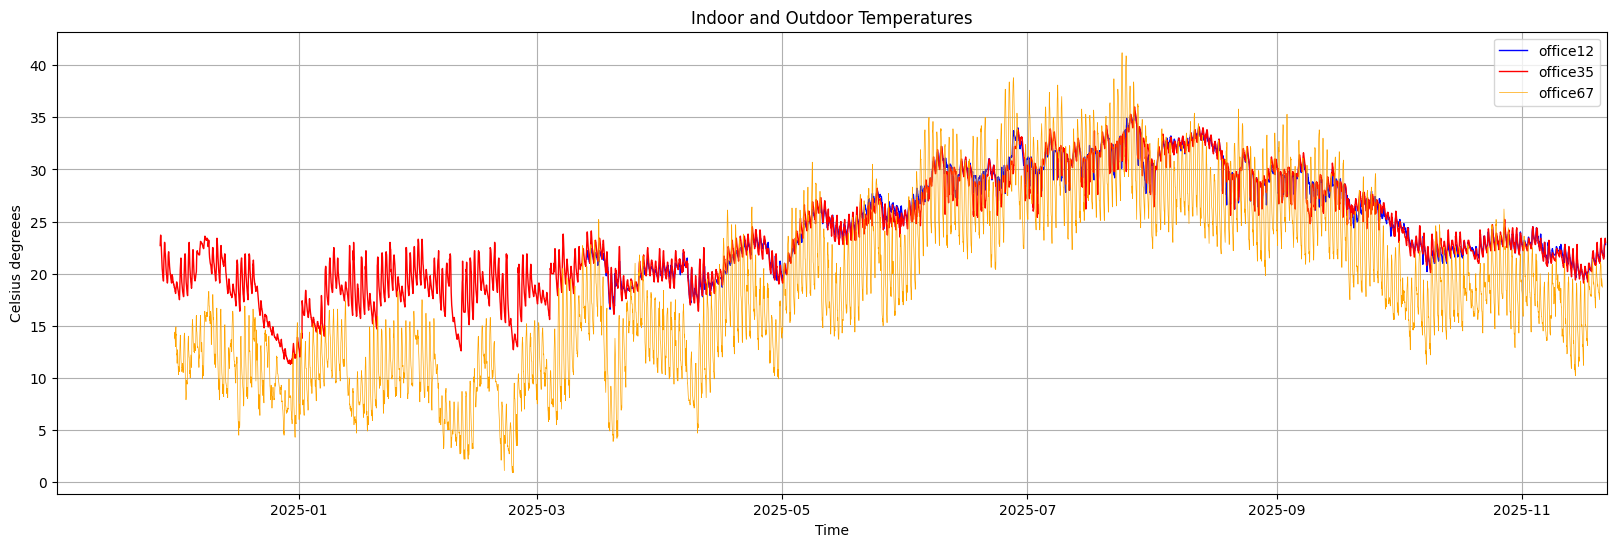

In [80]:
plt.figure(figsize=(20, 6))

plt.plot(temperatures.index, temperatures['o12_full'], color='blue', linewidth=1)
plt.plot(temperatures.index, temperatures['o35_full'], color='red', linewidth=1)
#plt.plot(temperatures.index, temperatures['o67_full'], color='green', linewidth=1)
plt.plot(df_tout['hour'], df_tout['T_out'], color='orange', linewidth=0.5)
plt.title("Indoor and Outdoor Temperatures")
plt.xlabel("Time")
plt.ylabel("Celsius degreees")
plt.grid(True)
plt.legend(['office12','office35','office67','outdoor'])
plt.xlim(pd.to_datetime('2024-11-01 19:00:00'), pd.to_datetime('2025-11-22 01:00:00'))